In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("BIED_Smart_Agriculture_Dataset.csv")
df.head()

,timestamp,device_id,location,crop_type,season,temperature,humidity,rainfall,soil_moisture,soil_ph,light_intensity,fertilizer_used,irrigation_needed,crop_health,yield_estimate,pest_risk,anomaly_flag
0,2024-01-01 00:00:00,BD-MYM-002,Mymensingh,Rice,winter,23.16,59.08,0.00,41.64,6.63,16.0,61.58,0,Healthy,4.29,Low,0
1,2024-01-01 00:00:00,BD-MYM-005,Mymensingh,Wheat,winter,23.79,56.87,0.00,57.24,6.57,52.0,11.52,0,Healthy,3.25,Low,0
2,2024-01-01 00:00:00,BD-RAJ-003,Rajshahi,Rice,winter,19.64,62.09,0.00,51.01,5.64,79.0,31.35,0,Healthy,4.67,Low,0
3,2024-01-01 01:00:00,BD-MYM-002,Mymensingh,Tomato,winter,18.68,52.33,14.87,75.14,6.26,68.0,24.17,0,Healthy,35.56,Low,0
4,2024-01-01 01:00:00,BD-CHA-001,Chattogram,Rice,winter,20.75,59.96,0.00,64.59,6.01,31.0,85.57,0,Healthy,4.40,Low,0


In [6]:
# 1. Проверка дубликатов
dups = df.duplicated().sum()
print(f"Найдено полных дубликатов: {dups}")

# 2. Проверка пропусков
missing = df.isna().sum().sum()
print(f"Найдено пропущенных значений: {missing}")

# 3. Проверка логических ошибок
logic_errors = 0
if (df['humidity'] > 100).any() or (df['humidity'] < 0).any(): logic_errors += 1
if (df['soil_moisture'] > 100).any() or (df['soil_moisture'] < 0).any(): logic_errors += 1
if (df['soil_ph'] < 0).any() or (df['soil_ph'] > 14).any(): logic_errors += 1
if (df['rainfall'] < 0).any(): logic_errors += 1
if (df['yield_estimate'] < 0).any(): logic_errors += 1

print(f"Найдено логических ошибок (нарушение физических границ): {logic_errors}")

Найдено полных дубликатов: 0
Найдено пропущенных значений: 0
Найдено логических ошибок (нарушение физических границ): 0


## Часть 1. Анализ данных (на 20% выборки)

**Логика:** Берем случайные 20% строк, чтобы имитировать работу с ограниченным объемом данных. Оставшиеся 80% будем использовать для проверки гипотез.

Для анализа возьмем два признака:
1. **`soil_moisture`** (влажность почвы) — ключевой фактор для роста растений.
2. **`yield_estimate`** (урожайность) — итоговый агрономический показатель.

In [8]:
# Берем 20% выборки
df_sample = df.sample(frac=0.2, random_state=42)
df_rest = df.drop(df_sample.index)  # Оставшиеся 80% для проверки гипотез

print(f"Размер выборки (20%): {len(df_sample)} строк")
print(f"Размер оставшейся части: {len(df_rest)} строк")

Размер выборки (20%): 2000 строк
Размер оставшейся части: 8000 строк


Text(0.5, 0, 'Влажность почвы (%)')

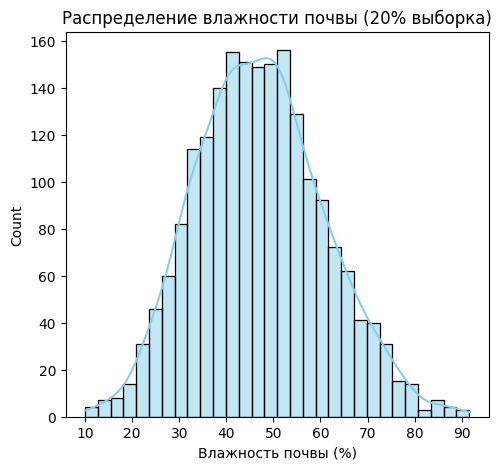

In [9]:
# Визуализация 1: Распределение влажности почвы
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df_sample['soil_moisture'], bins=30, kde=True, color='skyblue')
plt.title('Распределение влажности почвы (20% выборка)')
plt.xlabel('Влажность почвы (%)')

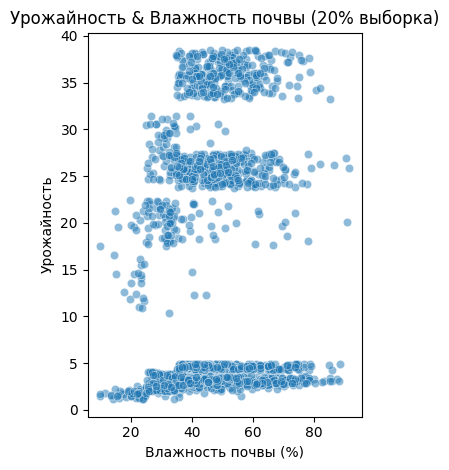

In [11]:
# Визуализация 2: Зависимость урожайности от влажности
plt.subplot(1, 2, 2)
sns.scatterplot(data=df_sample, x='soil_moisture', y='yield_estimate', alpha=0.5)
plt.title('Урожайность & Влажность почвы (20% выборка)')
plt.xlabel('Влажность почвы (%)')
plt.ylabel('Урожайность')
plt.tight_layout()
plt.show()

In [12]:
# Статистика
print("Статистика по выборке:")
print(f"soil_moisture — Среднее: {df_sample['soil_moisture'].mean():.2f}, Медиана: {df_sample['soil_moisture'].median():.2f}")
print(f"yield_estimate — Среднее: {df_sample['yield_estimate'].mean():.2f}, Медиана: {df_sample['yield_estimate'].median():.2f}")

Статистика по выборке:
soil_moisture — Среднее: 47.14, Медиана: 46.81
yield_estimate — Среднее: 13.01, Медиана: 4.42


### Формулировка гипотез на основе 20% выборки

1. **Гипотеза 1 :** График «Урожайность & Влажность» показывает четкие горизонтальные полосы (уровни урожайности ~4, ~25, ~37). Это означает, что урожайность в первую очередь определяется типом культуры (`crop_type`), а не только влажностью.
   * *Проверка:* Сравним среднюю урожайность по культурам на оставшихся 80% данных.
   
2. **Гипотеза 2:** Внутри каждой отдельной «полосы» (культуры) зависимость урожайности от влажности почвы слабая, так как точки разбросаны по всей оси X.
   * *Проверка:* Вычислим коэффициент корреляции Пирсона между `soil_moisture` и `yield_estimate` на оставшихся 80% данных. Ожидаем значение близкое к 0 (слабая связь).

3. **Гипотеза 3 :** Гистограмма влажности почвы показывает нормальное распределение со средним ~48%. Растения в критическом состоянии (`crop_health = Critical`) должны иметь влажность почвы значительно ниже среднего (в левом хвосте распределения).
   * *Проверка:* Сравним среднюю влажность почвы для групп Healthy и Critical на оставшихся 80% данных.

In [30]:
# Гипотеза 1
print("\nГипотеза 1: Средняя урожайность по культурам")
print(df_rest.groupby('crop_type')['yield_estimate'].mean().round(2))


Гипотеза 1: Средняя урожайность по культурам
crop_type
Jute       2.66
Potato    23.91
Rice       4.27
Tomato    33.33
Wheat      3.04
Name: yield_estimate, dtype: float64


In [27]:
# Гипотеза 2:
corr = df_rest['soil_moisture'].corr(df_rest['yield_estimate'])
print(f"\nГипотеза 2: Корреляция soil_moisture и yield_estimate = {corr:.3f}")


Гипотеза 2: Корреляция soil_moisture и yield_estimate = 0.109


In [28]:
# Гипотеза 3:
print("\nГипотеза 3: Средняя влажность почвы по crop_health")
print(df_rest.groupby('crop_health')['soil_moisture'].mean().round(2))


Гипотеза 3: Средняя влажность почвы по crop_health
crop_health
Critical    21.57
Healthy     51.79
Stressed    36.39
Name: soil_moisture, dtype: float64


### Вывод по результатам проверки гипотез (на 80% выборки)

1. **Гипотеза 1 — подтвердилась.**
   Анализ показал колоссальную разницу в урожайности: томаты дают в среднем 33.3 усл. ед., картофель — 23.9, в то время как рис, пшеница и джут — всего 2.6–4.3. Именно это создавало четкие горизонтальные полосы на точечном графике. Следовательно, `crop_type` является критически важным признаком для любых моделей, предсказывающих урожайность или здоровье.

2. **Гипотеза 2 — подтвердилась.**
   Коэффициент корреляции Пирсона составил 0.109. Это говорит о том, что глобальной линейной зависимости между влажностью почвы и объемом урожая нет. Урожайность — это комплексный показатель, который зависит от типа культуры, удобрений, pH и других факторов, а вода — лишь одно из условий.

3. **Гипотеза 3 — подтвердилась.**
   Обнаружена прямая и очевидная зависимость состояния растения от влажности почвы:
   - Здоровые (Healthy) — 51.8% влажности.
   - В стрессе (Stressed) — 36.4% влажности.
   - Критические (Critical) — 21.6% влажности.
   Это доказывает, что нехватка воды является главным триггером перехода растения в стрессовое и критическое состояние. Признак `soil_moisture` будет обладать высокой предсказательной силой для целевой переменной `crop_health`.

**Общий вывод:** 20% выборки оказалось достаточно для выявления скрытой структуры данных (мультимодальности из-за культур и водного стресса). Оставшиеся 80% данных полностью подтвердили выдвинутые гипотезы, что говорит об их высокой репрезентативности.

In [20]:
corr_spearman = df_rest['soil_moisture'].corr(df_rest['yield_estimate'], method='spearman')
print(f"Корреляция Спирмена: {corr_spearman:.3f}")

Корреляция Спирмена: 0.183


In [31]:
# Проверка корреляции Спирмена отдельно по культурам
print("Корреляция Спирмена (soil_moisture vs yield_estimate) по культурам:")
for crop in df_rest['crop_type'].unique():
    subset = df_rest[df_rest['crop_type'] == crop]
    corr = subset['soil_moisture'].corr(subset['yield_estimate'], method='spearman')
    print(f"{crop:10s}: {corr:.3f}")

Корреляция Спирмена (soil_moisture vs yield_estimate) по культурам:
Wheat     : 0.476
Rice      : 0.497
Tomato    : 0.464
Jute      : 0.453
Potato    : 0.439


### Дополнение к Гипотезе 2
Глобальная корреляция Спирмена между влажностью почвы и урожайностью составила 0.183, что говорит о слабой связи. Однако анализ scatter-графика показал, что данные образуют горизонтальные "полосы" (кластеры), соответствующие разным типам культур.

Чтобы исключить влияние генетических различий растений, мы рассчитали корреляцию отдельно для каждой культуры

**Вывод:** Мы наблюдаем классический парадокс Симпсона. Внутри каждой отдельной культуры связь между влажностью и урожаем является умеренной и устойчивой (~0.45–0.50). Глобальная корреляция была низкой (0.183) только потому, что мы смешали разные культуры в одну выборку, и огромный разброс базовой урожайности "замаскировал" реальное влияние воды.